# Chapitre 3 — Héritage, polymorphisme et surcharge
### Programmation avancée pour la Data Science — 2ème SDIA

**Objectif :** comprendre les mécanismes de POO qui permettent de lire et construire des architectures Python modulaires, notamment dans des contextes Data Science et IA.

À la fin de la séance, vous saurez :
- utiliser l’héritage et `super()` ;
- redéfinir des méthodes et exploiter le polymorphisme ;
- comprendre la surcharge en Python ;
- lire un héritage multiple avec le **MRO** ;
- comprendre le **Duck Typing** ;
- distinguer héritage et composition ;
- reconnaître les **Mixins** dans du code Python avancé.


# 1. Héritage et spécialisation


Exemple : `ModeleVision` **est un** `Modele`.


In [ ]:
class Modele:
    def __init__(self, nom):
        self.nom = nom

    def afficher(self):
        print("Modèle :", self.nom)


class ModeleVision(Modele):
    def analyser_image(self):
        print("Analyse d'une image")


modele = ModeleVision("VisionModel")

modele.afficher()
modele.analyser_image()


### Activité 1 — Compléter une spécialisation

Créer `ModeleTexte` qui hérite de `Modele`.

**TAF :**
1. compléter la déclaration de la classe ;
2. ajouter la méthode `generer_texte()` qui permet d'afficher "Génération de texte";
3. créer un objet ;
4. tester la méthode héritée et la nouvelle méthode.


In [ ]:
class Modele:
    def __init__(self, nom):
        self.nom = nom

    def afficher(self):
        print("Modèle :", self.nom)


class ModeleTexte(________):
    def __________________(______):
        _____________________________


modele = ______________________________ #créer un objet de type ModeleTexte

_______________________________________   #tester la méthode héritée sur l'objet madele

_______________________________________   #tester la nouvelle méthode sur l'objet madele


# 2. Constructeurs et `super()`

Lorsqu’une classe fille possède son propre constructeur, elle peut appeler le constructeur de la classe parent avec `super()`.

Ici, `super()` permet de poursuivre la recherche dans la hiérarchie d’héritage.


In [ ]:
class Modele:
    def __init__(self, nom):
        self.nom = nom


class ModeleTexte(Modele):
    def __init__(self, nom, langue):
        super().__init__(nom)
        self.langue = langue

modele = Modele("LLM-Texte")
modelT = ModeleTexte("LLM-Texte", "français")

print(modele.nom) #?
print(modelT.nom) #?
print(modelT.langue) #?
print(modele.langue) #?

### Activité 2 — `super()`

Compléter `ModeleImage` afin de conserver `nom` et d’ajouter `format_image`.


In [ ]:
class Modele:
    def __init__(self, nom):
        self.nom = nom


class ModeleImage(Modele):
    __________________________________
        ______________________________
        ______________________________


modelI = ModeleImage("VisionModel", "PNG")

print(modelI.nom)
print(modelI.format_image)


# 3. Redéfinition des méthodes — Override

Une classe fille peut **redéfinir** une méthode héritée pour proposer un comportement adapté.

C’est le principe d’**override**.


In [ ]:
class Modele:
    def predire(self):
        print("Prédiction générique")


class ModeleTexte(Modele):
    def predire(self):
        print("Prédiction à partir d'un texte")


class ModeleImage(Modele):
    def predire(self):
        print("Prédiction à partir d'une image")


texte = ModeleTexte()
image = ModeleImage()

# Appeler la méthode predire() de l'objet texte
________________________________________

# Appeler la méthode predire() de l'objet image
________________________________________


### Activité 3 — `Redéfinition de méthode`

- Ajouter à la classe `Modele` une méthode `pretraiter(donnee)` qui retourne la donnée telle quelle.
- Redéfinir cette méthode dans `ModeleTexte` pour transformer le texte en minuscules.
- Redéfinir cette méthode dans `ModeleImage` pour normaliser les valeurs des pixels.
- Tester la méthode sur une donnée textuelle et une donnée image.

In [ ]:
class Modele:
    def predire(self):
        print("Prédiction générique")

    # Ajouter la méthode pretraiter(donnee)
    ________________________________________


class ModeleTexte(Modele):
    def predire(self):
        print("Prédiction à partir d'un texte")

    # Redéfinir pretraiter(donnee)
    ________________________________________


class ModeleImage(Modele):
    def predire(self):
        print("Prédiction à partir d'une image")

    # Redéfinir pretraiter(donnee)
    ________________________________________


texte = ModeleTexte()
image = ModeleImage()

# Tester le prétraitement d'un texte
________________________________________

# Tester le prétraitement d'une image
________________________________________

---
# <span style="color:blue">Types d’héritage en Python</span>

- **simple** : une classe hérite d’une classe ;
- **multiniveau** : une classe hérite d’une classe fille ;
- **multiple** : une classe hérite de plusieurs classes.

L’héritage multiple permet notamment de comprendre le **MRO**.

---

---
## 1. Héritage simple

**Définition :** une classe hérite d’une seule classe mère.

**Exemple :** 


In [ ]:
class ModeleIA:
    def executer(self):
        print("Exécution du modèle IA")

class ModeleTexte(ModeleIA):
    def analyser_texte(self):
        print("Analyse du texte")


# Programme principal
modele = ModeleTexte()

modele.executer()       # Méthode héritée
modele.analyser_texte() # Méthode propre à la classe fille

**À retenir :** `ModeleTexte` hérite de la méthode `executer()` définie dans `ModeleIA`.

---
## 2. Héritage multiniveau

**Définition :** une classe hérite d’une classe fille, formant ainsi une chaîne d’héritage.

**Exemple :** 



In [ ]:
class ModeleIA:
    def executer(self):
        print("Exécution du modèle IA")


class ModeleTexte(ModeleIA):
    def analyser_texte(self):
        print("Analyse du texte")


class ModeleGeneration(ModeleTexte):
    def generer_texte(self):
        print("Génération d'un texte")
        
        
# Programme principal
modele = ModeleGeneration()

modele.executer()
modele.analyser_texte()
modele.generer_texte()

**À retenir :** `ModeleGeneration` hérite directement de `ModeleTexte` et indirectement de `ModeleIA`. Il peut donc utiliser les méthodes des deux classes.

---

## 3. Héritage multiple

**Définition :** une classe hérite de plusieurs classes mères.

**Exemple :** 




In [ ]:
class TraitementTexte:
    def analyser_texte(self):
        print("Analyse du texte")


class TraitementImage:
    def analyser_image(self):
        print("Analyse de l'image")


class ModeleMultimodal(TraitementTexte, TraitementImage):
    def executer(self):
        print("Traitement de plusieurs types de données")


# Programme principal
modele = ModeleMultimodal()

modele.analyser_texte()
modele.analyser_image()
modele.executer()

**À retenir :** `ModeleMultimodal` hérite des méthodes de `TraitementTexte` et de `TraitementImage`.

# 4. Polymorphisme


## <span style="color:blue">4.1. Polymorphisme de méthodes avec héritage</span>
Plusieurs classes filles héritent d'une même classe mère et redéfinissent une méthode héritée.

In [ ]:
class Modele:
    def predire(self, donnees):
        return(f"Prédiction générique: {donnees}")


class ModeleTexte(Modele):
    def predire(self, donnees):
        return(f"Prédiction texte : {donnees}")


class ModeleImage(Modele):
    def predire(self, donnees):
        return(f"Prédiction image : {donnees}")


def executer_prediction(modele, donnees):
    print(modele.predire(donnees))


executer_prediction(ModeleTexte(), "Bonjour")
executer_prediction(ModeleImage(), "image.png")

## <span style="color:blue">4.2. Polymorphisme avec une liste d'objets</span>

Le polymorphisme permet de parcourir une liste contenant des objets de différentes classes et d'appeler la même méthode sur chacun d'eux.

In [ ]:
class Modele:
    def predire(self, donnees):
        return(f"Prédiction générique: {donnees}")


class ModeleTexte(Modele):
    def predire(self, donnees):
        return(f"Prédiction texte : {donnees}")


class ModeleImage(Modele):
    def predire(self, donnees):
        return(f"Prédiction image : {donnees}")
    
# Liste d'objets de différentes classes 
modeles = [ModeleTexte(), ModeleImage(), Modele()] 

# Appel de la même méthode pour chaque objet 
for modele in modeles: 
    print(modele.predire("donnees"))


## <span style="color:blue">4.3. Polymorphisme sans héritage</span>
### **Le polymorphisme en Python ne nécessite pas obligatoirement l'héritage**. 

Deux classes indépendantes peuvent fournir une méthode portant le même nom et être utilisées de manière similaire.



In [ ]:
class ModeleTexte:
    def predire(self, donnees):
        return f"Prédiction texte : {donnees}"


class ModeleImage:
    def predire(self, donnees):
        return f"Prédiction image : {donnees}"


def executer_prediction(modele, donnees):
    return modele.predire(donnees)



print(executer_prediction(ModeleTexte(), "Bonjour"))
print(executer_prediction(ModeleImage(), "image.png"))

## <span style="color:blue">4.4. Polymorphisme des opérateurs</span>

Le polymorphisme des opérateurs signifie qu'un même opérateur peut réaliser des opérations différentes selon les types d'objets utilisés.

In [ ]:
print(3 + 4) 
print("Data" + "Science")

## <span style="color:blue">À retenir</span>

* **Avec héritage :** les classes filles peuvent redéfinir une méthode héritée.
* **Avec une liste d'objets :** une même méthode peut être appelée sur plusieurs objets de classes différentes.
* **Sans héritage :** des objets de classes indépendantes peuvent être utilisés de manière uniforme s'ils possèdent les méthodes attendues.
* **Avec les opérateurs :** un même opérateur peut avoir des comportements différents selon les types d'objets.


# 5. Surcharge en Python

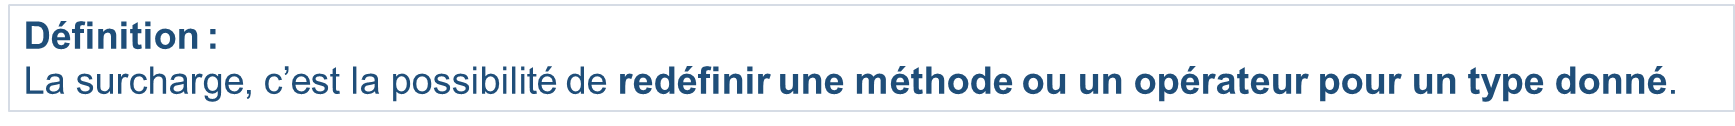

## <span style="color:blue">5.1 Surcharge de méthodes</span>

Dans certains langages, la surcharge permet de définir plusieurs méthodes portant le même nom avec des paramètres différents.

Python ne conserve pas plusieurs méthodes de même nom uniquement parce que leurs paramètres sont différents.

In [ ]:
class Calcul:
    def additionner(self, a, b):
        return a + b

    def additionner(self, a, b, c):
        return a + b + c
    
c = Calcul()

c.additionner(2, 3) #??

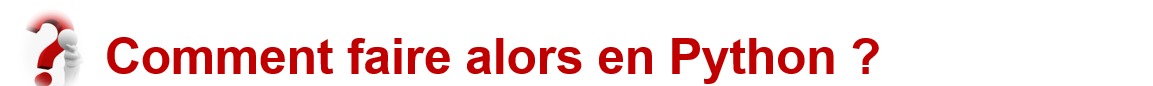

En Python, on peut obtenir des comportements similaires à la **surcharge des méthodes** en utilisant notamment :

- les paramètres par défaut 
- `*args` 
- `**kwargs`

### Exemple 1 — paramètres par défaut

In [ ]:
class Calcul:
    def additionner(self, a, b, c=0):
        return a + b + c
    
c = Calcul()

print(c.additionner(2, 3))
print(c.additionner(2, 3, 4))

### Exemple 2 — Surcharge avec *args

In [ ]:
class Calcul:
    def additionner(self, *nombres):
        return sum(nombres)
    
c = Calcul()

print(c.additionner(2, 3))
print(c.additionner(2, 3, 4))
print(c.additionner(2, 3, 4, 5))

### Exemple 3 — Surcharge avec **kwargs

In [ ]:
class Calcul:
    def additionner(self, **kwargs):
        return sum(kwargs.values())


# Programme principal
calcul = Calcul()

print(calcul.additionner(a=2, b=3))
print(calcul.additionner(a=2, b=3, c=4))

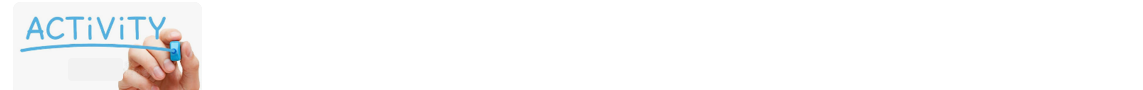

### Activité — Surcharge de méthodes en Python

On souhaite développer une classe `Generateur` permettant de simuler la génération de texte avec une température configurable et des paramètres supplémentaires.

**TAF :**

1. Définir une méthode `generer()` avec les paramètres suivants :

   * `texte` : chaîne vide par défaut ;
   * `temperature` : valeur `0.7` par défaut ;
   * `*args` : pour recevoir des paramètres supplémentaires ;
   * `**kwargs` : pour recevoir des options nommées supplémentaires.
2. Afficher le texte, la température, les paramètres supplémentaires et les options reçues.
3. Tester la méthode avec les appels suivants :

```python
g.generer()
g.generer("Bonjour")
g.generer("Bonjour", 0.9)
g.generer("Bonjour", 0.8, "français", "court",
          modele="GPT", style="formel")
```


In [ ]:
#Votre Solution



## <span style="color:blue">5.2 Surcharge des opérateurs</span>
Python permet également de redéfinir le comportement des opérateurs pour les objets d'une classe.

Cette technique est appelée **surcharge des opérateurs**.

En Python, la surcharge des opérateurs se fait via des **méthodes spéciales** :

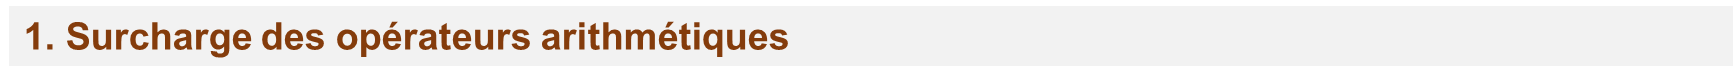
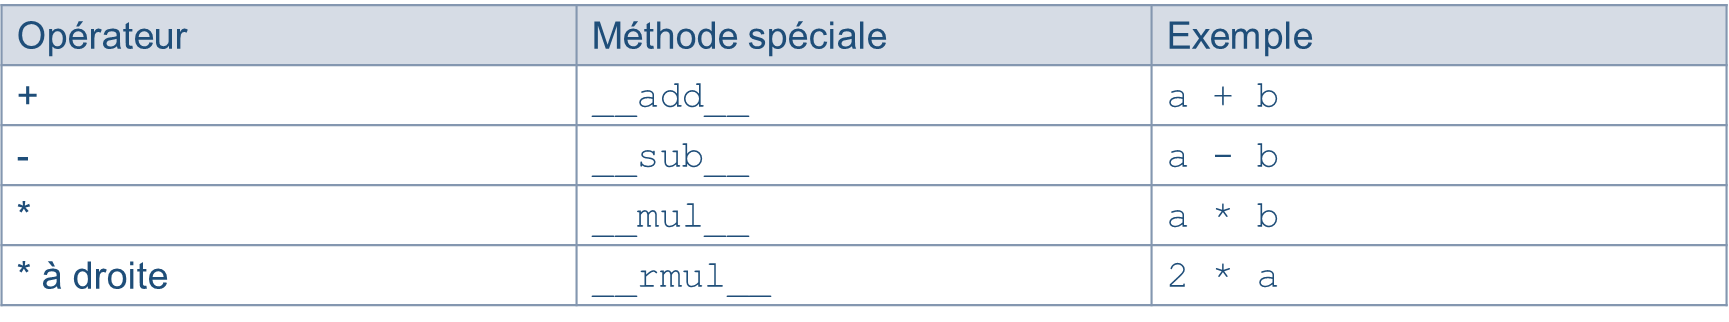

In [ ]:
class Rectangle:
    def __init__(self, largeur, hauteur):
        self.largeur = largeur
        self.hauteur = hauteur

    def aire(self):
        return self.largeur * self.hauteur

    def __mul__(self, facteur):
        return Rectangle(self.largeur * facteur,
                         self.hauteur * facteur)

    def __rmul__(self, facteur):
        return self.__mul__(facteur)

    def __str__(self):
        return f"Rectangle({self.largeur}, {self.hauteur})"


r = Rectangle(3, 4)

print(2 * r)
print(r * 2)

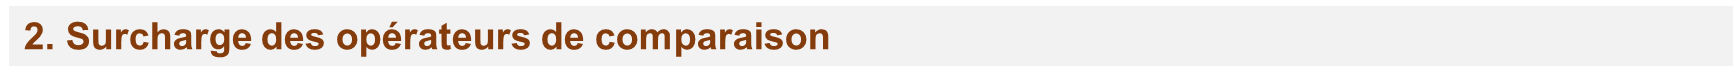
Ces opérateurs permettent de **comparer des objets**. En Python, on peut surcharger ces opérateurs avec des méthodes spéciales :

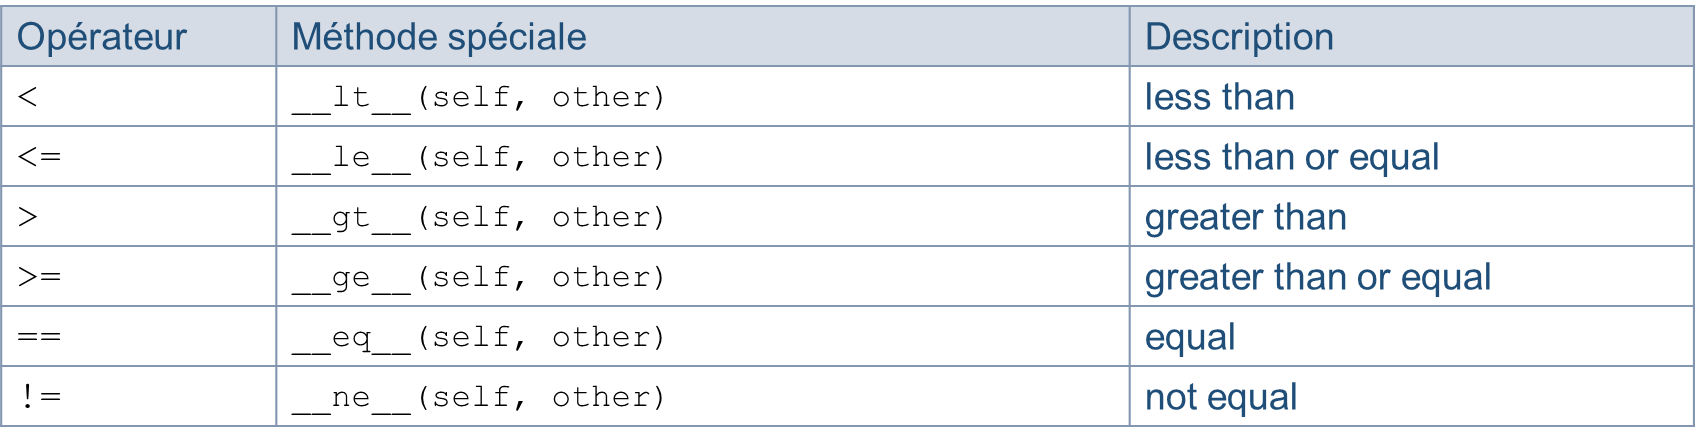

In [ ]:
class Rectangle:
    def __init__(self, largeur, hauteur):
        self.largeur = largeur
        self.hauteur = hauteur

    def aire(self):
        return self.largeur * self.hauteur

    def __lt__(self, other):
        return self.aire() < other.aire()

r1 = Rectangle(2,3)
r2 = Rectangle(4,5)

print(r1 < r2)  # True, car 6 < 20
# < est surchargé via __lt__ et permet de comparer les rectangles par leur aire.

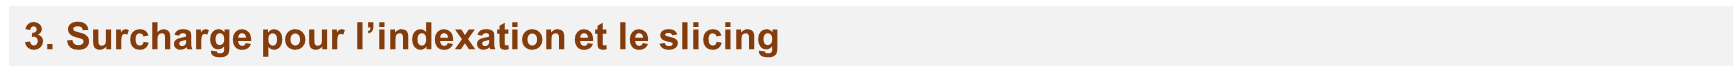
Python permet de surcharger **l’accès aux éléments d’un objet** avec des méthodes spéciales :

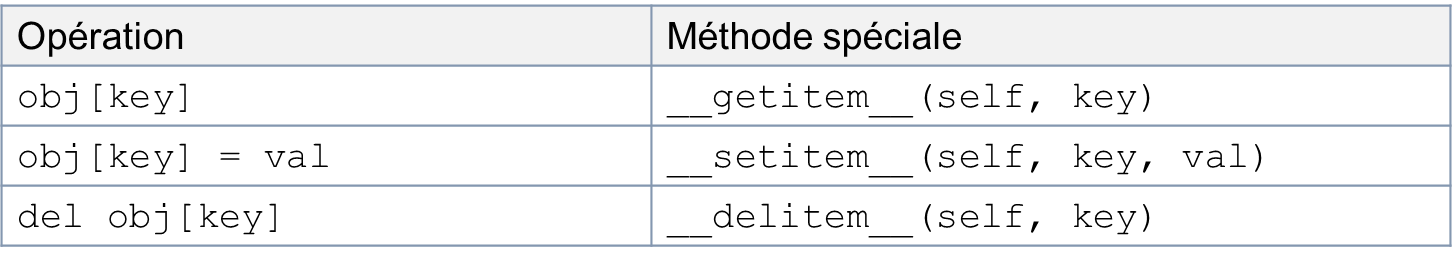

In [ ]:
class ParcRectangles:
    def __init__(self):
        self.rects = []

    def ajouter(self, r):
        self.rects.append(r)

    def __getitem__(self, index):
        return self.rects[index]

    def __setitem__(self, index, value):
        self.rects[index] = value

p = ParcRectangles()
p.ajouter(Rectangle(2,3))
p.ajouter(Rectangle(4,5))

# Afficher le rectangle d'indice 0
_______________________

# Remplacer le rectangle d'indice 1 par Rectangle(1, 1)
_______________________


# Afficher le rectangle d'indice 1 après modification
_______________________


## <span style="color:blue">5.3 Autres méthodes spéciales</span>

In [ ]:
class ModeleIA:
    def __init__(self, nom, temperature):
        self.nom = nom
        self.temperature = temperature

    def __repr__(self):
        return f"ModeleIA(nom={self.nom!r}, temperature={self.temperature!r})"


modele = ModeleIA("GPT", 0.7)

print(modele) # l’exécution de print fait appel à la méthode __repr__ 

print(repr(modele))

modele ## l’exécution de l’évaluation de modele fait appel à __repr__ 

In [ ]:
class ModeleIA:
    def __init__(self, nom, temperature):
        self.nom = nom
        self.temperature = temperature

    def __str__(self):
        return f"Modèle IA : {self.nom}"

    
modele = ModeleIA("GPT", 0.7)

print(modele) # l’exécution de print fait appel à la méthode __str__ 

modele #sans redéfinir __repr__ l’exécution renvoie la référence de l’objet 

In [ ]:
class ModeleIA:
    def __init__(self, nom, temperature):
        self.nom = nom
        self.temperature = temperature

    def __str__(self):
        return f"Modèle IA : {self.nom}"

    def __repr__(self):
        return f"ModeleIA(nom={self.nom!r}, temperature={self.temperature!r})"


modele = ModeleIA("GPT", 0.7)

print(modele) # l’exécution de print fait appel à la méthode __str__ 

modele # l’exécution de l’évaluation de modele fait appel à __repr__ 

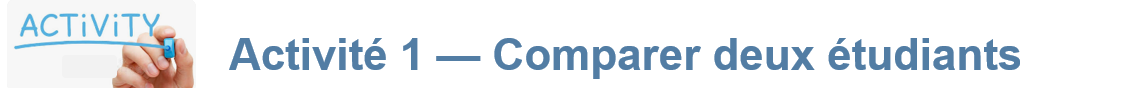


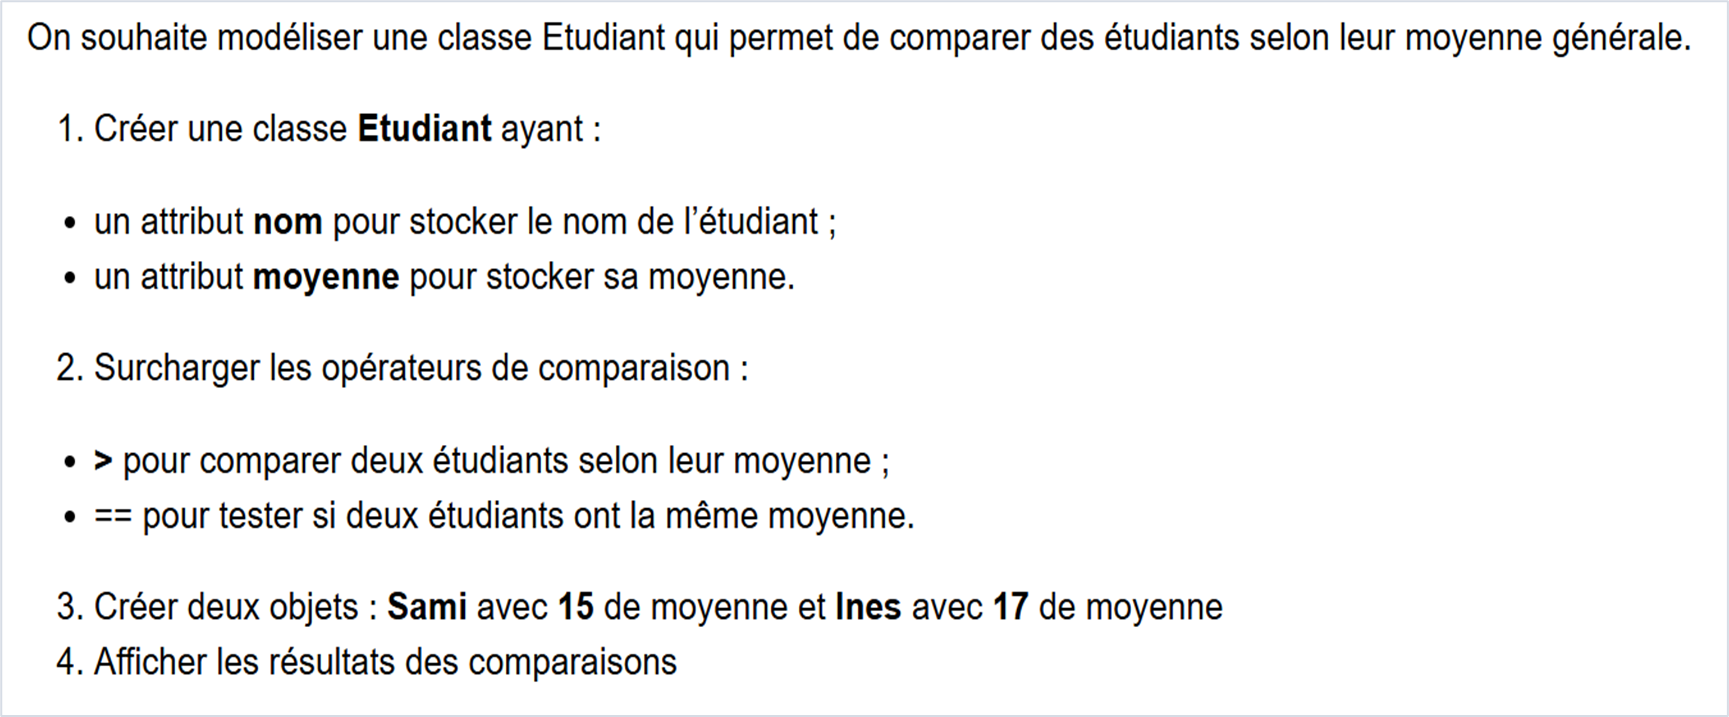

In [ ]:
#Votre Solution




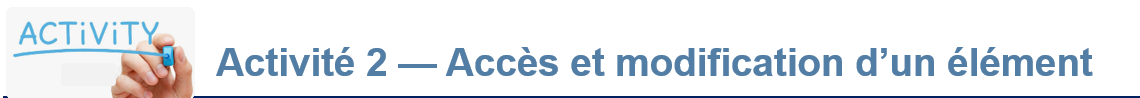

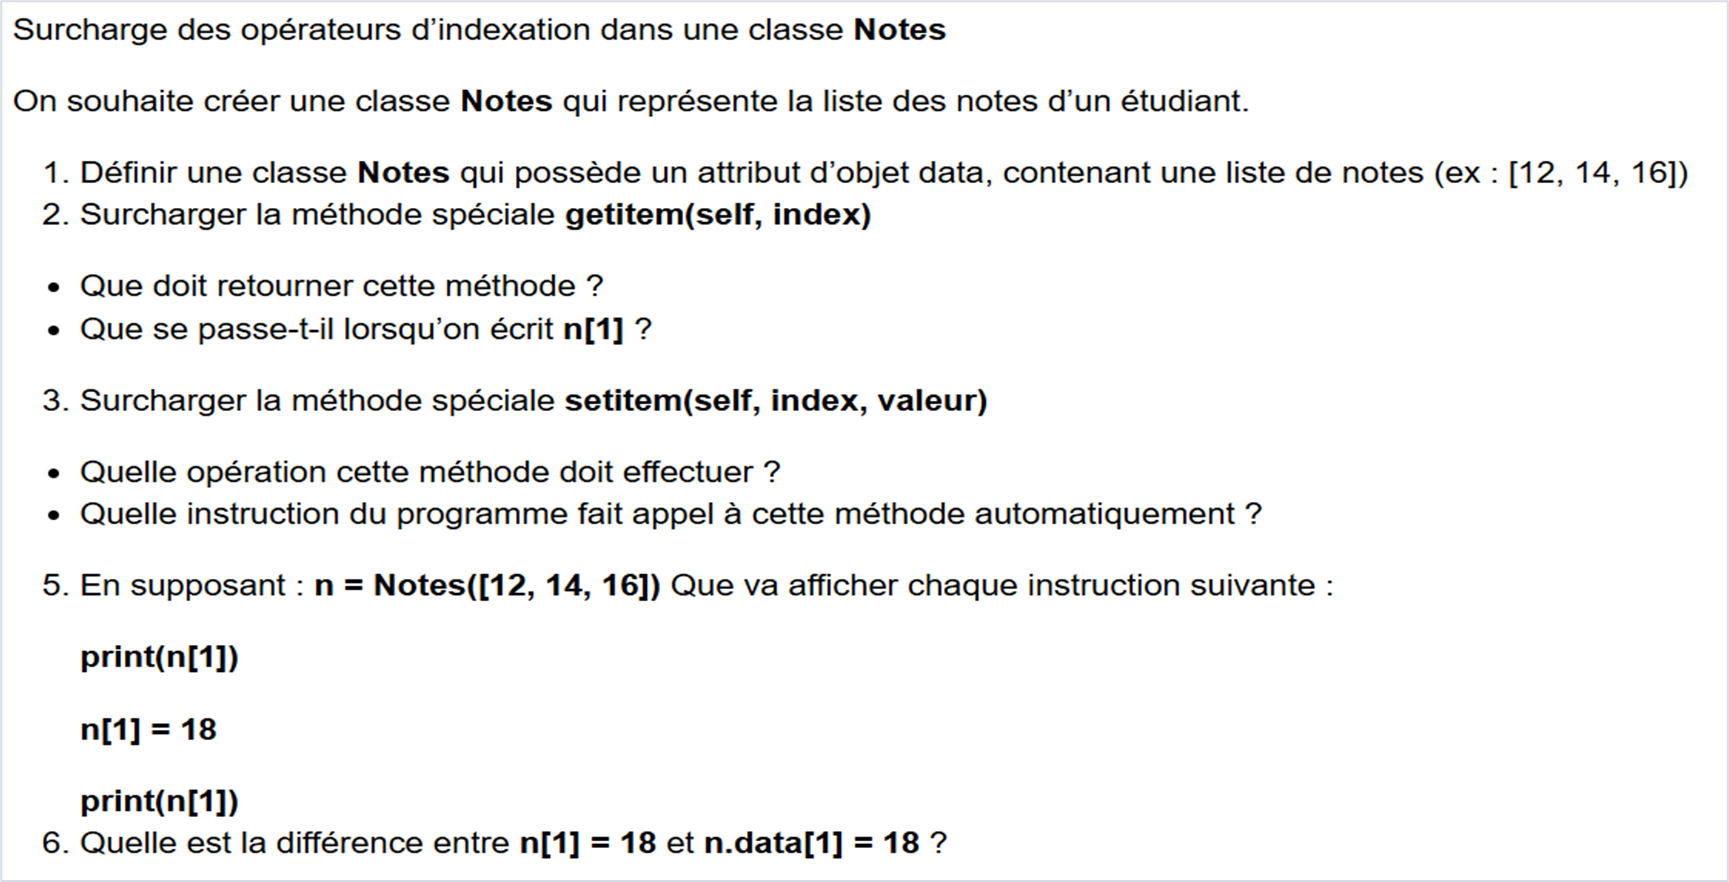

In [ ]:
#Votre solution 




# 6. Héritage multiple et MRO

1. **Rappel Héritage multiple** : une classe peut hériter de plusieurs classes mères.

```python
class D(B, C):
    ...
```

2. **Le problème à étudier** : Que se passe-t-il lorsque plusieurs classes mères possèdent une méthode portant le même nom ?

3. Le **MRO (Method Resolution Order)** : expliquer **l’ordre dans lequel Python recherche une méthode** et montrer comment consulter cet ordre avec **Classe.mro()**.

In [ ]:
class A:
    def afficher(self):
        print("Classe A")


class B(A):
    def afficher(self):
        print("Classe B")


class C(A):
    def afficher(self):
        print("Classe C")


class D(B, C):
    pass


objet = D()
objet.afficher()

print(D.mro())

# 7. `super()` et héritage multiple

Avec plusieurs niveaux ou plusieurs classes, `super()` suit le **MRO**.

Il ne faut donc pas retenir seulement :

> `super()` = « appeler le parent »

Il est plus juste de retenir :

> `super()` = poursuivre la recherche de méthode selon le MRO.


In [ ]:
class A:
    def afficher(self):
        print("A")


class B(A):
    def afficher(self):
        print("B")
        super().afficher()


class C(A):
    def afficher(self):
        print("C")
        super().afficher()


class D(B, C):
    def afficher(self):
        print("D")
        super().afficher()


objet = D()
objet.afficher()

Pourquoi ? 
Le MRO de D est :

In [ ]:
print(D.mro())

# 8. Duck Typing

Le **Duck Typing** repose sur l’idée suivante :

> Si un objet possède le comportement dont j’ai besoin, je peux l’utiliser.

Deux classes n’ont donc pas nécessairement besoin d’avoir un ancêtre commun.


In [ ]:
class LLM:
    def generer(self):
        print("Le LLM génère du texte")


class Agent:
    def generer(self):
        print("L'agent génère une réponse")


def lancer(objet):
    objet.generer()


lancer(LLM())
lancer(Agent())

# 9. Héritage ou composition ?

### Exemple : un agent IA qui utilise un LLM
Un agent IA peut utiliser un LLM pour générer du texte. 

L'agent n'est pas lui-même un LLM : il **possède un LLM qu'il utilise**. La composition est donc adaptée.

In [ ]:
class LLM:
    def generer(self, message):
        return f"Réponse générée pour : {message}"


class Agent:
    def __init__(self, modele):
        self.modele = modele

    def repondre(self, message):
        return self.modele.generer(message)


# Programme principal
llm = LLM()
agent = Agent(llm)

print(agent.repondre("Bonjour"))

# A retenir
| **Héritage**                                | **Composition**                                 |
| ------------------------------------------- | ----------------------------------------------- |
| Relation « est un type de » (*is-a*)        | Relation « possède ou utilise » (*has-a*)       |
| `ModeleTexte` hérite de `ModeleIA`.         | `Agent` utilise un objet `LLM`.                 |
| Permet de spécialiser une classe existante. | Permet de combiner des composants indépendants. |


# 10. Mixins


**Exemple** : ajouter une fonctionnalité de journalisation.


In [ ]:
class LoggerMixin:
    def log(self, message):
        print("[LOG]", message)


class Agent(LoggerMixin):
    def executer(self):
        self.log("Début de l'exécution")
        print("Exécution de l'agent")

# Programme principal
agent = Agent()
agent.executer()

# 11. Activité — Développer un mini-système de traitement de données

### Contexte

Une application de traitement de données doit exécuter différentes opérations, journaliser leur exécution et exporter les résultats au format JSON. Le système doit rester modulaire pour faciliter l'ajout de nouvelles fonctionnalités.

On dispose de deux classes permettant d’effectuer deux opérations différentes.

In [ ]:
class Analyse:
    def executer(self):
        return "Analyse des données"


class Journal:
    def executer(self):
        return "Journalisation de l'opération"

### Partie 1 — Héritage multiple et MRO

**TAF 1 :** Compléter le code suivant pour créer une classe `AnalyseTrace` qui hérite des deux classes `Analyse` et `Journal`.


In [ ]:
# Créer la classe AnalyseTrace 
class __________________:
    pass

**TAF 2 :** Créer un objet `objet` de la classe `AnalyseTrace`, puis appeler sa méthode `executer()`.

In [ ]:
# Créer un objet de la classe AnalyseTrace
objet = __________________

# Appeler la méthode executer()
print(__________________)

**TAF 3 :** Afficher l'ordre de résolution des méthodes (MRO) de la classe `AnalyseTrace`.

In [ ]:
print(__________________)


**Questions :**

1. Quel message est affiché lors de l'appel à `executer()` ?
2. Les deux classes possèdent une méthode portant le même nom. Pourquoi Python choisit-il cette implémentation ?
3. Quel est l'ordre de résolution des méthodes de `AnalyseTrace` ?

### Partie 2 — Utiliser `super()` dans un pipeline de traitement

**Objectif :** Construire un pipeline qui exécute plusieurs étapes successives en utilisant `super()` et l'ordre de résolution des méthodes (MRO).

On souhaite obtenir l'affichage suivant lors de l'exécution du pipeline :

```text
Début du pipeline
Étape A : préparation des données
Étape B : traitement des données
Fin du pipeline
```

**TAF 1 :** Compléter les méthodes `executer()` des classes `EtapeA`, `EtapeB` et `FinPipeline` afin d'obtenir le résultat souhaité. Les deux premières étapes doivent appeler `super().executer()` pour transmettre l'exécution à l'étape suivante.

In [ ]:
class EtapeA:
    def executer(self):
        # Afficher "Étape A : préparation des données"
        print(____________________________)

        # Passer à l'étape suivante
        ____________________________


class EtapeB:
    def executer(self):
        # Afficher "Étape B : traitement des données"
        print(____________________________)

        # Passer à l'étape suivante
        ____________________________


class FinPipeline:
    def executer(self):
        # Afficher "Fin du pipeline"
        print(____________________________)


**TAF 2 :** Créer une classe `Pipeline` qui hérite de `EtapeA`, `EtapeB` et `FinPipeline`. Redéfinir sa méthode `executer()` pour afficher le début du pipeline, puis transmettre l'exécution à la première étape.

In [ ]:
# Définir la classe Pipeline
class ______________________________:
    def executer(self):
        # Afficher "Début du pipeline"
        print(____________________________)

        # Lancer la première étape
        ____________________________

**TAF 3 :** Créer un objet `pipeline` et appeler sa méthode `executer()`.

In [ ]:
# Créer un objet Pipeline
pipeline = ____________________________

# Exécuter le pipeline
____________________________

**Questions :**

1. Quel est l'ordre d'exécution des méthodes ?
2. Quel est le rôle de `super().executer()` dans les classes `EtapeA`, `EtapeB` et `Pipeline` ?
3. Pourquoi la méthode `executer()` de `FinPipeline` est-elle appelée en dernier ?


### Partie 3 — Polymorphisme et Duck Typing

**Objectif :** Exécuter une opération sur différents objets sans vérifier explicitement leur classe, à condition qu'ils possèdent la méthode attendue.

On dispose des deux classes suivantes :

In [ ]:
class TraitementCSV:
    def traiter(self):
        return "Traitement du fichier CSV"


class TraitementJSON:
    def traiter(self):
        return "Traitement du fichier JSON"

**TAF 1 :** Compléter la fonction `lancer_traitement(objet)` pour qu'elle appelle la méthode appropriée de l'objet reçu et retourne son résultat.

In [ ]:
def lancer_traitement(objet):
    return ____________________________

**TAF 2 :** Créer une liste contenant un objet de chaque classe, puis écrire une boucle `for` pour parcourir la liste et afficher le résultat de chaque traitement en utilisant la fonction `lancer_traitement()`.

In [ ]:
# Créer la liste des traitements
traitements = ____________________________

# Parcourir la liste et afficher les résultats
________________________________________
________________________________________

**TAF 3 :** Créer une nouvelle classe `TraitementXML` possédant une méthode `traiter()` qui retourne `"Traitement du fichier XML"`. Créer un objet de cette classe et le tester avec la fonction `lancer_traitement()`, sans modifier cette fonction.


In [ ]:
# Définir la classe TraitementXML
________________________________________

# Créer un objet et tester la fonction
________________________________________
________________________________________

**Questions :**

1. Pourquoi la même fonction `lancer_traitement()` peut-elle traiter des objets de classes différentes ?
2. Pourquoi `TraitementXML` fonctionne-t-elle sans hériter de `TraitementCSV` ou de `TraitementJSON` ?
3. Quelle condition un objet doit-il respecter pour être accepté par `lancer_traitement()` ?


## Partie 4 — Mixin et export JSON
**Objectif :** Réutiliser une même méthode d'export JSON dans plusieurs classes, sans recopier son code.

On souhaite pouvoir convertir les objets `Rapport` et `Configuration` en chaînes JSON à l'aide d'une méthode commune `vers_json()`.

**TAF 1 :** Compléter la classe `JSONMixin` pour que sa méthode `vers_json()` convertisse les attributs de l'objet en une chaîne au format JSON.

In [ ]:
import json

class JSONMixin:
    def vers_json(self):
        return json.dumps(____________________)

**TAF 2 :** Compléter les classes suivantes pour représenter un rapport et une configuration. Les deux classes doivent bénéficier de la méthode `vers_json()` sans la redéfinir.


In [ ]:
class Rapport(JSONMixin):
    def __init__(self, titre, resultat):
        self.titre = ____________
        self.resultat = ____________


class Configuration(JSONMixin):
    def __init__(self, nom, format_sortie):
        self.nom = ____________
        self.format_sortie = ____________

**TAF 3 :** Créer un objet `rapport` avec le titre `"Analyse des données"` et le résultat `"Succès"`, puis un objet `configuration` avec le nom `"Export quotidien"` et le format `"JSON"`. Afficher leur représentation JSON en utilisant la méthode `vers_json()`.

In [ ]:
# Créer les deux objets
rapport = ______________________________________
configuration = _________________________________

# Afficher leur représentation JSON
_______________________________________________
_______________________________________________

**Questions :**

1. Pourquoi les classes `Rapport` et `Configuration` peuvent-elles utiliser `vers_json()` sans la redéfinir ?
2. Quel est l'avantage du mixin par rapport à la duplication du code ?


## Partie 5 — Composition : construire un pipeline de traitement
**Objectif :** Construire une classe qui utilise un objet de traitement sans hériter de sa classe.

On souhaite créer un pipeline capable d'exécuter différents traitements en lui fournissant un objet possédant une méthode `traiter()`.

On dispose de la classe suivante :

In [ ]:
class TraitementCSV:
    def traiter(self):
        return "Traitement du fichier CSV"

**TAF 1 :** Compléter la classe `PipelineTraitement`. Son constructeur doit mémoriser l'objet de traitement reçu, et sa méthode `executer()` doit appeler la méthode `traiter()` de cet objet.


In [ ]:
class PipelineTraitement:
    def __init__(self, traitement):
        self.traitement = ____________________

    def executer(self):
        return ______________________________

**TAF 2 :** Créer un objet `TraitementCSV`, l'utiliser pour construire un objet `PipelineTraitement`, puis afficher le résultat de l'exécution du pipeline.


In [ ]:
# Créer l'objet de traitement
traitement = ______________________________

# Construire le pipeline
pipeline = ________________________________

# Exécuter le pipeline
__________________________________________

**TAF 3 :** Réutiliser la classe `PipelineTraitement` avec un objet de la classe `TraitementJSON` de la partie 3, sans modifier `PipelineTraitement`.



**Question :** Pourquoi la composition est-elle intéressante ici, plutôt que de faire hériter `PipelineTraitement` de `TraitementCSV` ?
